# Results 4 — Broader application identifies conserved synergistic markers in other conditions

Input: `synergy_by_cohort.tsv` (one row per cohort × directed pair that passed the Bonferroni pair threshold and the synergy filter in ≥ 6 of 10 MDFS runs; built by `load_cohort_data.py` from `results/`). All counts in this notebook are on **unordered pairs** (orientation with the larger total IG), see `load_synergies()`.
Outputs: `../manuscript/Figure5.{pdf,png}`, `../manuscript/Table1_validation_cohorts.tsv`, `../manuscript/SuppTable4_conserved_pairs.tsv`, `top_markers_per_cohort.txt`, `emergent_synergies_table.tsv`; the counts quoted in the Results text are printed by the Table 1 cell and the cells below it.


In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
CRC_COHORTS = {"VogtmannE_2016", "WirbelJ_2018", "YachidaS_2019", "YuJ_2015", "ZellerG_2014"}


def load_synergies(path="synergy_by_cohort.tsv"):
    """Synergy table (one row per cohort x directed pair, pairs present in >= 6 of 10 MDFS runs),
    reduced to ONE row per cohort x unordered pair: MDFS reports every pair in both orientations
    (base -> contributing and contributing -> base) with different base_IG_1D / IG_2D_added but the
    same total_IG; the manuscript counts unique pairs, so the orientation with the larger total IG
    (ties: the first) is kept and `pair_key` identifies the unordered pair."""
    s = pd.read_csv(path, sep="\t")
    s = s[~s["cohort"].isin(CRC_COHORTS)].copy()
    s["pair_key"] = [" + ".join(sorted((str(a), str(b)))) for a, b in zip(s["base"], s["contributing"])]
    s = s.sort_values("total_IG_mean", ascending=False).drop_duplicates(["cohort", "pair_key"]).reset_index(drop=True)
    return s

synergies = load_synergies()
print(synergies.shape)
print(f"Retained {len(synergies)} pairs from {synergies['cohort'].nunique()} non-CRC cohorts")
print(synergies["cohort"].unique().tolist())
# Table for copy-paste to Excel/Word
_syn_copy = synergies.sort_values(by='ig_gain_pct', ascending=False)
_syn_copy = _syn_copy[["cohort", "base", "contributing", "base_IG_1D_mean", "total_IG_mean", "ig_gain_pct"]].head(30)
print(_syn_copy.to_csv(sep="\t", index=False))
print("(Copy the output above and paste into Excel or Word; tabs will align as columns.)")

(87124, 11)
Retained 87124 pairs from 8 non-CRC cohorts
['QinN_2014', 'HallAB_2017', 'MetaCardis_2020_a', 'JieZ_2017', 'RubelMA_2020', 'NielsenHB_2014', 'NagySzakalD_2017', 'ZhuF_2020']
cohort	base	contributing	base_IG_1D_mean	total_IG_mean	ig_gain_pct
QinN_2014	P261-PWY:_coenzyme_M_biosynthesis_I	Streptococcus_anginosus_group	1.52587890625e-05	81.62445068359376	534933899.9999998
QinN_2014	PWY-6113:_superpathway_of_mycolate_biosynthesis	Streptococcus_anginosus_group	1.52587890625e-05	81.62445068359376	534933899.9999998
QinN_2014	PWY-6524:_lychnose_and_isolychnose_biosynthesis	Streptococcus_anginosus_group	1.52587890625e-05	81.62445068359376	534933899.9999998
QinN_2014	Lactobacillus_harbinensis	Streptococcus_anginosus_group	1.52587890625e-05	81.62445068359376	534933899.9999998
QinN_2014	Oligella_ureolytica	Streptococcus_anginosus_group	1.52587890625e-05	81.62445068359376	534933899.9999998
QinN_2014	PWY-3781:_aerobic_respiration_I_(cytochrome_c)	Streptococcus_anginosus_group	1.5258789062

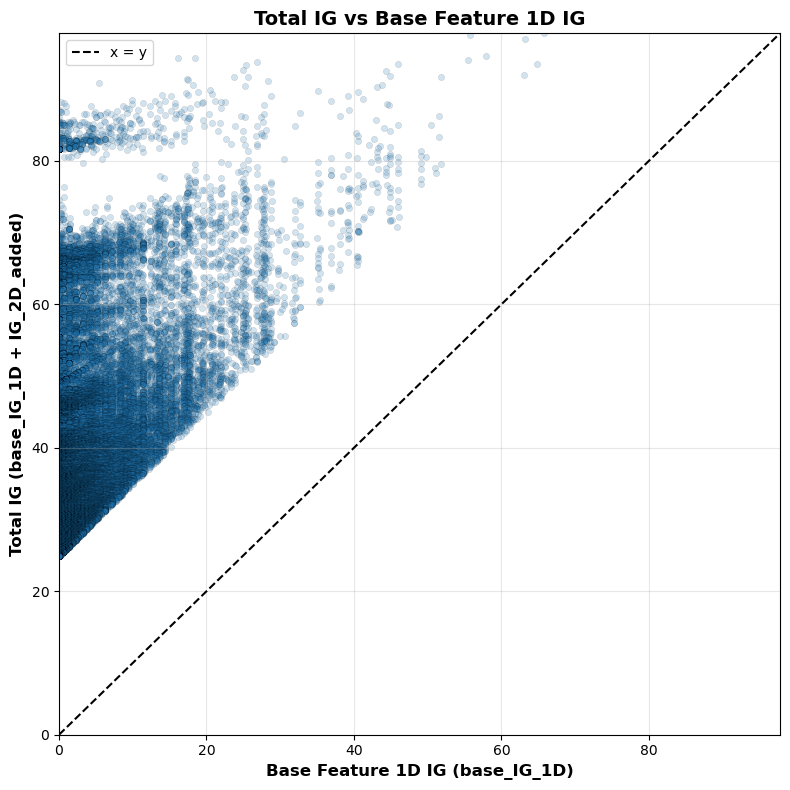

In [3]:
# Scatter: x = base feature 1D IG, y = total IG (base + 2D added); dashed x=y line
fig, ax = plt.subplots(figsize=(8, 8))
x = synergies["base_IG_1D_mean"].astype(float)
y = synergies["total_IG_mean"].astype(float)
ax.scatter(x, y, alpha=0.2, s=20, edgecolors="k", linewidths=0.3)
xy_min = min(x.min(), y.min())
xy_max = max(x.max(), y.max())
ax.plot([xy_min, xy_max], [xy_min, xy_max], "k--", linewidth=1.5, label="x = y")
ax.set_xlabel("Base Feature 1D IG (base_IG_1D)", fontsize=12, fontweight="bold")
ax.set_ylabel("Total IG (base_IG_1D + IG_2D_added)", fontsize=12, fontweight="bold")
ax.set_title("Total IG vs Base Feature 1D IG", fontsize=14, fontweight="bold")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
ax.set_xlim(xy_min, xy_max)
ax.set_ylim(xy_min, xy_max)
plt.tight_layout()
plt.show()

### Alternative ways to present synergy results

- **Color by strength**: Scatter with points colored by `ig_gain_pct` (green = strong 2D gain, red = weak) so strength is visible at a glance.
- **By cohort**: Bar chart of number of synergy pairs per cohort — shows which cohorts contribute most.
- **Two-panel figure**: Scatter (total IG vs base 1D IG) + cohort summary in one figure.
- **Top-N table**: Sort by `ig_gain_pct` or `total_IG_mean` and report top 10–20 pairs (with cohort, base, contributing) for the main text or supplement.
- **Distribution**: Histogram of `ig_gain_pct` to show how 2D IG gain is distributed.
- **Log scale**: If IGs span orders of magnitude, use log-scale axes so points are not clustered near zero.

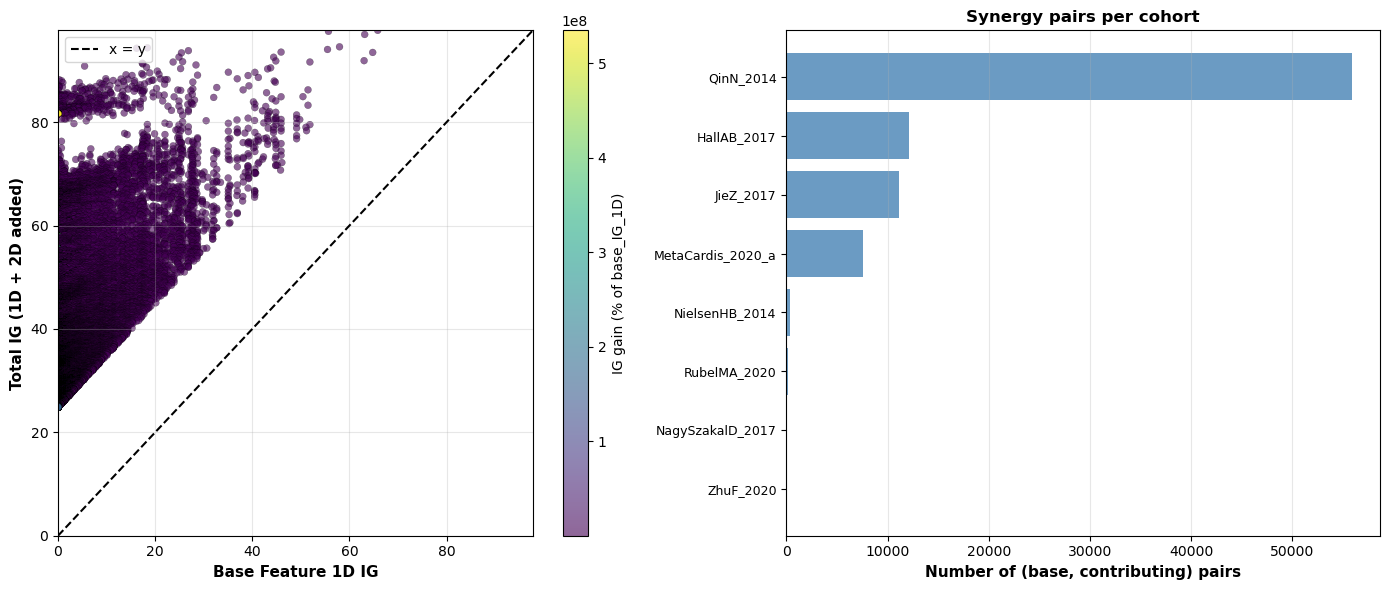

In [4]:
# Two-panel figure: scatter (colored by IG gain strength) + bar chart (synergy count per cohort)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panel 1: Scatter with color = ig_gain_pct (2D IG gain strength)
ax = axes[0]
x = synergies["base_IG_1D_mean"].astype(float)
y = synergies["total_IG_mean"].astype(float)
c = synergies["ig_gain_pct"].astype(float)
sc = ax.scatter(x, y, c=c, cmap="viridis", alpha=0.6, s=25, edgecolors="k", linewidths=0.2)
xy_min = min(x.min(), y.min())
xy_max = max(x.max(), y.max())
ax.plot([xy_min, xy_max], [xy_min, xy_max], "k--", linewidth=1.5, label="x = y")
ax.set_xlabel("Base Feature 1D IG", fontsize=11, fontweight="bold")
ax.set_ylabel("Total IG (1D + 2D added)", fontsize=11, fontweight="bold")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
ax.set_xlim(xy_min, xy_max)
ax.set_ylim(xy_min, xy_max)
plt.colorbar(sc, ax=ax, label="IG gain (% of base_IG_1D)")

# Panel 2: Synergy pairs per cohort
ax2 = axes[1]
cohort_counts = synergies["cohort"].value_counts()
cohort_counts = cohort_counts.sort_values(ascending=True)
ax2.barh(range(len(cohort_counts)), cohort_counts.values, color="steelblue", alpha=0.8)
ax2.set_yticks(range(len(cohort_counts)))
ax2.set_yticklabels(cohort_counts.index, fontsize=9)
ax2.set_xlabel("Number of (base, contributing) pairs", fontsize=11, fontweight="bold")
ax2.set_title("Synergy pairs per cohort", fontsize=12, fontweight="bold")
ax2.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

**Figure caption (for paper)**  
*2D information gain across validation cohorts.* Left: Total IG (base_IG_1D + IG_2D_added) versus base feature 1D IG for each (base, contributing) pair; points above the dashed line (x = y) indicate positive 2D gain (the contributing variable improves the base feature's IG). Colour indicates the IG gain as % of base_IG_1D. Right: Number of (base, contributing) pairs per cohort. Cohorts are independent validation sets not used for pipeline training.

**Methodology (short)**  
We applied the MDFS framework to each validation cohort separately: combined taxonomic and functional (pathway) abundances were used as features, and binary labels (control/healthy vs. disease) from cohort metadata. For each cohort, MDFS was run three times with different random seeds; 1D IGs, 2D significance, and ComputeInterestingTuples pair-level IGs were averaged across runs. The 2D IG is additional — it represents how much the contributing variable improves the base feature's information gain beyond its 1D baseline. The left panel shows total_IG vs base_IG_1D; the right panel summarizes how many significant (base, contributing) pairs were found per cohort.

In [5]:
# Top 15 pairs by IG gain % (for reporting / supplement)
top_n = 15
display_df = synergies.nlargest(top_n, "ig_gain_pct").copy()
cols = [c for c in ["cohort", "base", "contributing", "base_IG_1D_mean", "total_IG_mean", "IG_2D_added_mean", "ig_gain_pct"] if c in display_df.columns]
display_df[cols].round(4)

,cohort,base,contributing,base_IG_1D_mean,total_IG_mean,IG_2D_added_mean,ig_gain_pct
443,QinN_2014,PWY-7283:_wybutosine_biosynthesis,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0
444,QinN_2014,Subdoligranulum_variabile,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0
445,QinN_2014,PWY-5178:_toluene_degradation_IV_(aerobic)_(vi...,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0
446,QinN_2014,PWY-6948:_sitosterol_degradation_to_androstene...,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0
447,QinN_2014,PWY0-1338:_polymyxin_resistance,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0
448,QinN_2014,PWY-5863:_superpathway_of_phylloquinol_biosynt...,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0
449,QinN_2014,PWY-6969:_TCA_cycle_V_(2-oxoglutarate:ferredox...,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0
450,QinN_2014,NONMEVIPP-PWY:_methylerythritol_phosphate_path...,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0
451,QinN_2014,Staphylococcus_saprophyticus,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0
452,QinN_2014,PWY-5705:_allantoin_degradation_to_glyoxylate_III,Streptococcus_anginosus_group,0.0,81.6245,81.6244,534933900.0


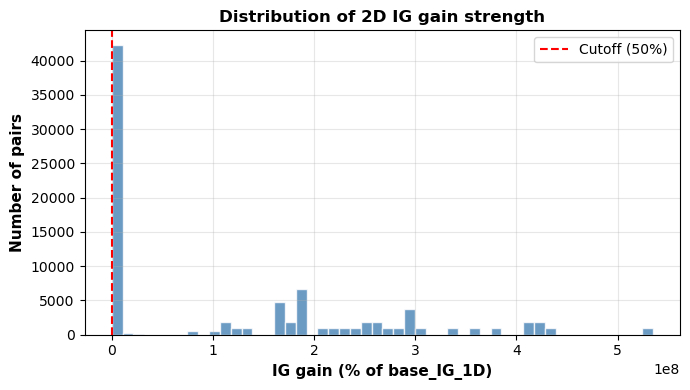

In [6]:
# Distribution of IG gain strength (% above base 1D IG)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(synergies["ig_gain_pct"].dropna().astype(float), bins=50, color="steelblue", alpha=0.8, edgecolor="white")
ax.axvline(50, color="red", linestyle="--", linewidth=1.5, label="Cutoff (50%)")
ax.set_xlabel("IG gain (% of base_IG_1D)", fontsize=11, fontweight="bold")
ax.set_ylabel("Number of pairs", fontsize=11, fontweight="bold")
ax.set_title("Distribution of 2D IG gain strength", fontsize=12, fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
synergies = synergies.loc[synergies['ig_gain_pct'] >= 50]
print(synergies.shape)

(83313, 11)


In [8]:
# Check pairs where base feature has zero 1D IG (pure 2D gain)
print(synergies.loc[synergies['base_IG_1D_mean'] == 0].shape)
print(synergies.loc[synergies['base_IG_1D_mean'] == 0][["cohort", "base", "contributing"]].to_string())

(0, 11)
Empty DataFrame
Columns: [cohort, base, contributing]
Index: []


In [9]:
print(synergies.loc[synergies['base_IG_1D_mean'] == 0].sort_values(by='ig_gain', ascending=False).to_string())

Empty DataFrame
Columns: [cohort, base, contributing, base_IG_1D_mean, contributing_IG_1D_mean, IG_2D_added_mean, total_IG_mean, n_runs, ig_gain, ig_gain_pct, pair_key]
Index: []


In [10]:
# Pairs with high total_IG but low base_IG_1D (strong 2D gain, weak individual signal)
subset = synergies[(synergies["total_IG_mean"].astype(float) > 60) & (synergies["base_IG_1D_mean"].astype(float) < 10)]
print(f"Pairs with total_IG > 60 and base_IG_1D < 10: {len(subset)}")
print(subset.to_string())

Pairs with total_IG > 60 and base_IG_1D < 10: 8167


           cohort                                                                                                         base                   contributing  base_IG_1D_mean  contributing_IG_1D_mean  IG_2D_added_mean  total_IG_mean  n_runs    ig_gain   ig_gain_pct                                                                                                                                     pair_key
21      QinN_2014                                             PWY-7220:_adenosine_deoxyribonucleotides_de_novo_biosynthesis_II  Streptococcus_anginosus_group         5.469181                84.943497         85.385381      90.854562       8  85.385381  1.561210e+03                                             PWY-7220:_adenosine_deoxyribonucleotides_de_novo_biosynthesis_II + Streptococcus_anginosus_group
38      QinN_2014                                                                                 Bacteroides_cellulosilyticus  Streptococcus_anginosus_group         9.835056            

In [11]:
subset = synergies[(synergies["total_IG_mean"].astype(float) > 85) & (synergies["base_IG_1D_mean"].astype(float) < 40)]
print(subset.to_string())

          cohort                                                                                          base                   contributing  base_IG_1D_mean  contributing_IG_1D_mean  IG_2D_added_mean  total_IG_mean  n_runs    ig_gain   ig_gain_pct                                                                                                                      pair_key
4      QinN_2014                                                                         Clostridium_symbiosum  Streptococcus_anginosus_group        18.390840                81.624420         76.011483      94.402323      10  76.011483  4.133116e+02                                                                         Clostridium_symbiosum + Streptococcus_anginosus_group
5      QinN_2014                                                                         Clostridium_aldenense  Streptococcus_anginosus_group        16.197203                81.624420         78.112057      94.309261      10  78.112057  4.822565e+0

In [12]:
# Top 20 markers (base, contributing pairs) by total_IG per cohort; save to one file with cohort and disease
n_top = 20
cols = ["base", "contributing", "total_IG_mean", "base_IG_1D_mean", "IG_2D_added_mean"]

cohort_iter = synergies["cohort"].unique()
get_sub = lambda c: synergies[synergies["cohort"] == c]

# Optional: load disease/condition per cohort from metadata
cohort_to_disease = {}
for meta_path in ["data/merged_metadata.tsv", "merged_metadata.tsv"]:
    try:
        meta = pd.read_csv(meta_path, sep="\t", low_memory=False, nrows=100000)
        cohort_col = next((c for c in ["source_cohort", "study_name"] if c in meta.columns), None)
        label_col = next((c for c in ["study_condition", "disease"] if c in meta.columns), None)
        if cohort_col and label_col:
            for c in meta[cohort_col].dropna().unique():
                vals = meta.loc[meta[cohort_col].astype(str) == str(c), label_col].dropna().unique().tolist()
                cohort_to_disease[str(c).strip()] = "; ".join(sorted(set(str(v) for v in vals))) if vals else ""
        break
    except Exception:
        continue

# Build combined dataframe and save to top_markers_per_cohort.txt
rows = []
for cohort in sorted(cohort_iter):
    sub = get_sub(cohort)
    top = sub.nlargest(n_top, "total_IG_mean").copy()
    top["disease"] = cohort_to_disease.get(cohort, "")
    top["rank_in_cohort"] = range(1, len(top) + 1)
    rows.append(top)
top_markers_per_cohort = pd.concat(rows, ignore_index=True)
out_cols = ["cohort", "disease", "rank_in_cohort", "base", "contributing", "total_IG_mean", "base_IG_1D_mean", "IG_2D_added_mean"]
if "ig_gain_pct" in top_markers_per_cohort.columns:
    out_cols.append("ig_gain_pct")
top_markers_per_cohort = top_markers_per_cohort[[c for c in out_cols if c in top_markers_per_cohort.columns]]
top_markers_per_cohort.to_csv("top_markers_per_cohort.txt", sep="\t", index=False)
print(f"Saved {len(top_markers_per_cohort)} rows to top_markers_per_cohort.txt")

for cohort in sorted(cohort_iter):
    sub = get_sub(cohort)
    top = sub.nlargest(n_top, "total_IG_mean")
    display_cols = [c for c in cols if c in top.columns]
    print(f"\n{'='*80}\n{cohort} — top {n_top} by total_IG\n{'='*80}")
    print(top[display_cols].to_string())

Saved 123 rows to top_markers_per_cohort.txt

HallAB_2017 — top 20 by total_IG
                               base                                                             contributing  total_IG_mean  base_IG_1D_mean  IG_2D_added_mean
20          Coprobacter_fastidiosus                                                           Coprobacter_sp      91.080215        28.406754         62.673462
23            Clostridium_lavalense                                                     Alistipes_putredinis      90.521343        43.781781         46.739562
216        Bacteroides_intestinalis                                                    Clostridium_lavalense      83.849875        27.405193         56.444682
1393                 Coprobacter_sp                                                    Bacteroides_coprocola      81.415009        49.128510         32.286499
1404                 Coprobacter_sp                                                     Alistipes_putredinis      80.728307   

In [13]:
# Table 1 / Results 4: validation cohorts - sample counts, whether MDFS was run, number of unordered synergistic pairs
import glob, os, sys
sys.path.insert(0, ".")
from load_cohort_data import EXCLUDED_CRC_COHORTS
meta = pd.read_csv("data/merged_metadata.tsv", sep="\t", low_memory=False)
cohort_col = next(k for k in ["source_cohort", "study_name"] if k in meta.columns)
label_col = next(k for k in ["study_condition", "disease"] if k in meta.columns)
lab = meta[label_col].astype(str).str.strip().str.lower()
meta["_label"] = np.where(lab.isin(["control", "healthy"]), "control", np.where(lab.isin(["nan", ""]), "unlabelled", "disease"))
tab = meta.groupby(cohort_col)["_label"].value_counts().unstack(fill_value=0).reset_index().rename(columns={cohort_col: "cohort"})
for k in ("disease", "control", "unlabelled"):
    if k not in tab.columns: tab[k] = 0
tab["conditions"] = tab["cohort"].map(cohort_to_disease)
analysed = {os.path.basename(f)[len("ig_gain_summary_"):-4] for f in glob.glob("results/ig_gain_summary_*.tsv")}
_all = load_synergies()
n_pairs = _all.groupby("cohort")["pair_key"].nunique()
n_pairs50 = _all[_all["ig_gain_pct"] >= 50].groupby("cohort")["pair_key"].nunique()
def status(r):
    if r["cohort"] in EXCLUDED_CRC_COHORTS: return "excluded (CRC cohort of the discovery arm)"
    if r["cohort"] not in analysed: return "not analysed (no profiles, < 10 samples or a single label class)"
    return "analysed"
tab["status"] = tab.apply(status, axis=1)
tab["n_synergistic_pairs"] = tab["cohort"].map(n_pairs).fillna(0).astype(int)
tab["n_pairs_gain_ge_50pct"] = tab["cohort"].map(n_pairs50).fillna(0).astype(int)
tab = tab[["cohort", "conditions", "disease", "control", "unlabelled", "status", "n_synergistic_pairs", "n_pairs_gain_ge_50pct"]]
tab = tab.sort_values(["status", "n_synergistic_pairs"], ascending=[True, False]).reset_index(drop=True)
tab.to_csv("../manuscript/Table1_validation_cohorts.tsv", sep="\t", index=False)
print(tab.to_string())
print(f"\nanalysed: {(tab.status == 'analysed').sum()}; with >= 1 pair: {((tab.status == 'analysed') & (tab.n_synergistic_pairs > 0)).sum()}; "
      f"unique pairs over all cohorts: {_all['pair_key'].nunique():,}; "
      f"pairs with >= 100 % gain in >= 1 cohort: {_all.loc[_all['ig_gain_pct'] >= 100, 'pair_key'].nunique():,}")


_label                  cohort                                                                                                                                                                                                  conditions  disease  control  unlabelled                                                            status  n_synergistic_pairs  n_pairs_gain_ge_50pct
0                    QinN_2014                                                                                                                                                                                          cirrhosis; control      123      114           0                                                          analysed                55853                  55850
1                  HallAB_2017                                                                                                                                                                                                IBD; control      185       

/var/folders/14/cbbyp9td0gl7qft267hmvqs00000gn/T/ipykernel_31666/1168630689.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=_ridge_df, x="cohort", y="total_ig_pct_median", order=cohorts_ord, palette=palette_joy, ax=axes[1], width=0.8)


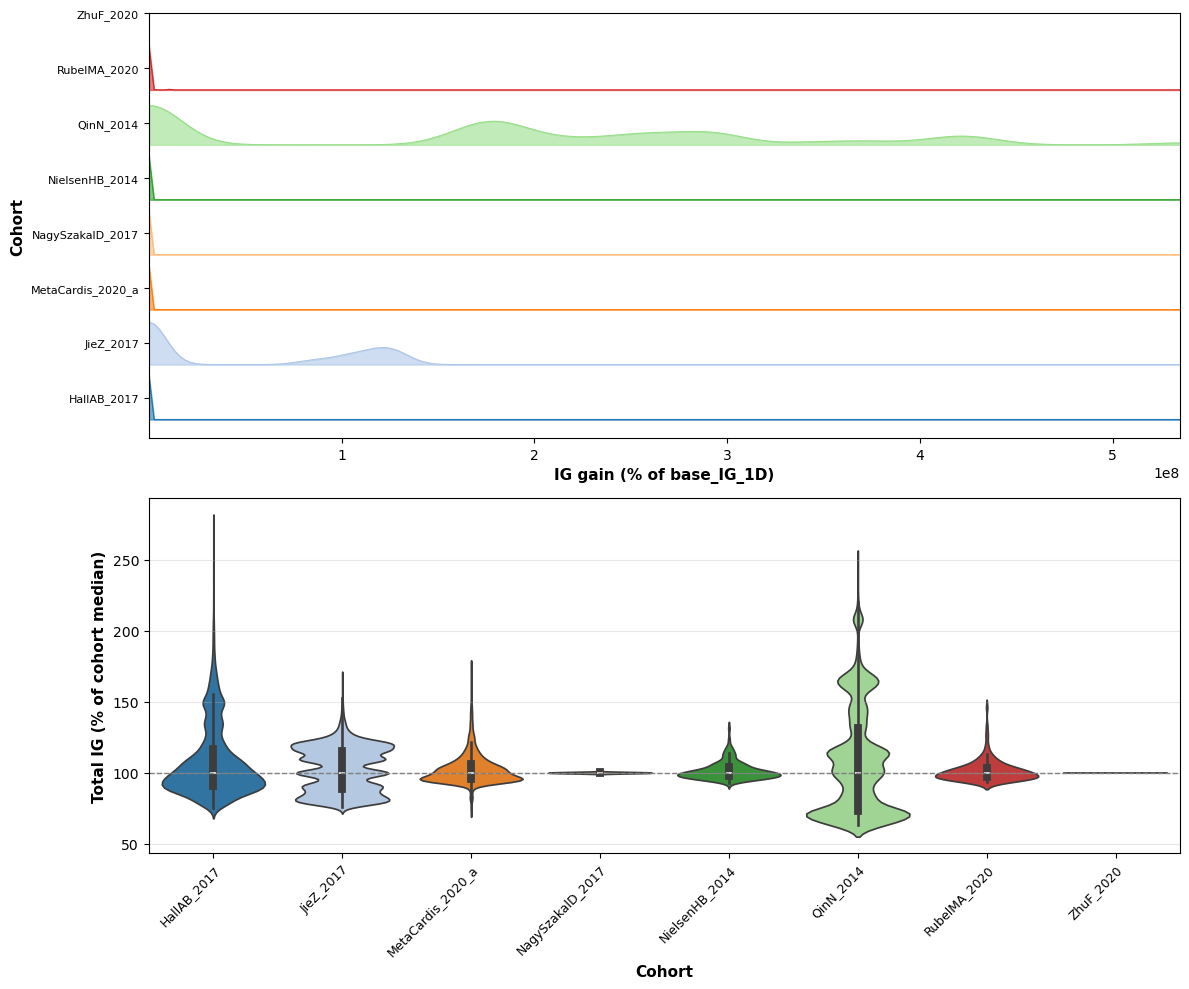

In [14]:
# One figure: top = ridge plot (IG gain %), bottom = boxplots (total_IG by cohort), same colours
_ridge_df = synergies.copy()
_ridge_df["total_IG_mean"] = _ridge_df["total_IG_mean"].astype(float)
_ridge_df["base_IG_1D_mean"] = _ridge_df["base_IG_1D_mean"].astype(float)
# ig_gain_pct is already in the data; use it directly
_ridge_df = _ridge_df.dropna(subset=["ig_gain_pct", "cohort", "total_IG_mean"])
_ridge_df["total_ig_pct_median"] = (_ridge_df["total_IG_mean"] / _ridge_df.groupby("cohort")["total_IG_mean"].transform("median")) * 100
_ridge_c = _ridge_df[_ridge_df["total_IG_mean"] >= 5]
cohorts_ord = sorted(_ridge_c["cohort"].unique())
palette_joy = sns.color_palette("tab20", n_colors=len(cohorts_ord))

fig, axes = plt.subplots(2, 1, figsize=(12, 10), height_ratios=[1.2, 1])
# --- Top: Ridge plot (IG gain %), restricted to total_IG >= 5 ---
from scipy.stats import gaussian_kde
ax_ridge = axes[0]
_xlo, _xhi = np.nanpercentile(_ridge_c["ig_gain_pct"].dropna(), [1, 99])
x_shared = np.linspace(_xlo, _xhi, 200)
for i, c in enumerate(cohorts_ord):
    vals = _ridge_c.loc[_ridge_c["cohort"] == c, "ig_gain_pct"].dropna().values
    if len(vals) < 2:
        continue
    kde = gaussian_kde(vals)
    dens = kde(x_shared)
    dens = dens / (dens.max() + 1e-9) * 0.8
    y_off = i * 1.0
    ax_ridge.fill_between(x_shared, y_off, y_off + dens, alpha=0.6, color=palette_joy[i])
    ax_ridge.plot(x_shared, y_off + dens, color=palette_joy[i], linewidth=0.8)
ax_ridge.axvline(0, color="gray", linestyle="--", linewidth=1.5)
ax_ridge.set_xlim(_xlo, _xhi)
ax_ridge.set_yticks(np.arange(len(cohorts_ord)) + 0.4)
ax_ridge.set_yticklabels(cohorts_ord, fontsize=8)
ax_ridge.set_xlabel("IG gain (% of base_IG_1D)", fontsize=11, fontweight="bold")
ax_ridge.set_ylabel("Cohort", fontsize=11, fontweight="bold")
# --- Bottom: Violin plots of total_IG as % of cohort median (median = 100%) ---
sns.violinplot(data=_ridge_df, x="cohort", y="total_ig_pct_median", order=cohorts_ord, palette=palette_joy, ax=axes[1], width=0.8)
axes[1].axhline(100, color="gray", linestyle="--", linewidth=1)
axes[1].set_ylabel("Total IG (% of cohort median)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Cohort", fontsize=11, fontweight="bold")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="x", which="major", labelsize=9)
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
axes[1].grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

/var/folders/14/cbbyp9td0gl7qft267hmvqs00000gn/T/ipykernel_31666/1714627346.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=_full, x="cohort", y="total_ig_pct_median", order=cohorts_ord_d, palette=palette_d, ax=axes[1, 1], width=0.8)


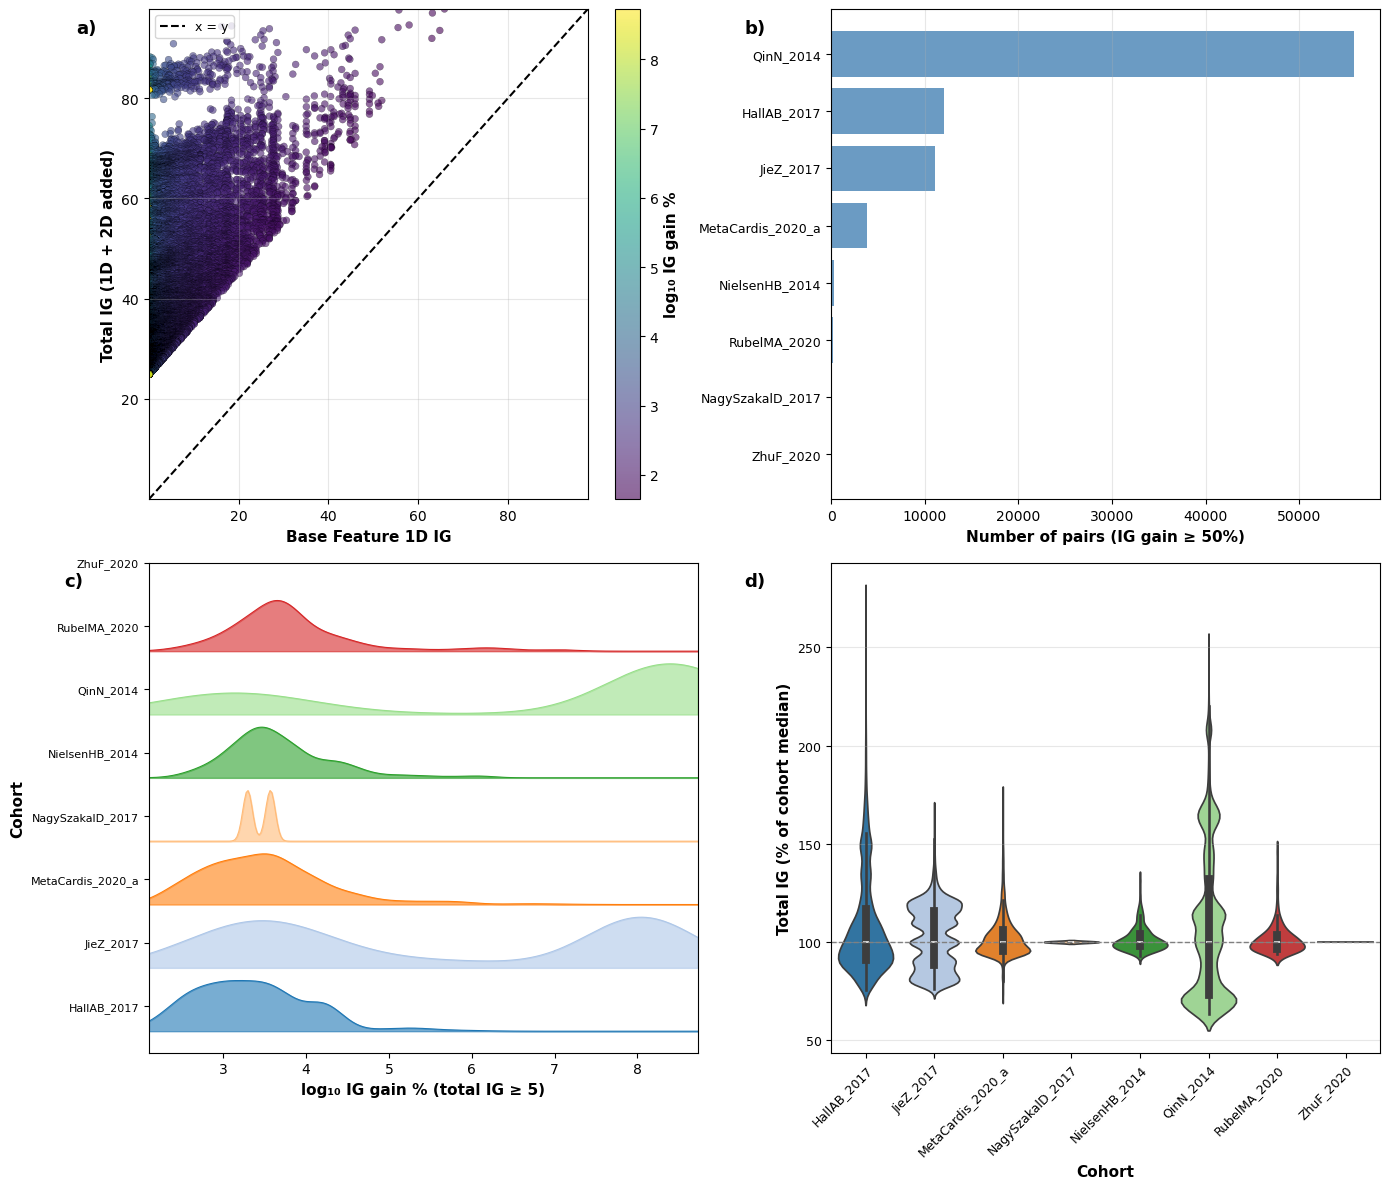

Saved figure5_synergy_gains.pdf/.png


In [15]:
# Combined figure: (a) scatter, (b) pairs per cohort (ig_gain_pct>=50), (c) ridge (total_IG>=5), (d) violin
# Re-read full data so this cell is independent of upstream filters
from scipy.stats import gaussian_kde

CRC_COHORTS = {"VogtmannE_2016", "WirbelJ_2018", "YachidaS_2019", "YuJ_2015", "ZellerG_2014"}
_full = load_synergies()
_full["total_IG_mean"] = _full["total_IG_mean"].astype(float)
_full["base_IG_1D_mean"] = _full["base_IG_1D_mean"].astype(float)
_full = _full.dropna(subset=["ig_gain_pct", "cohort", "total_IG_mean"])
_full["total_ig_pct_median"] = (_full["total_IG_mean"] / _full.groupby("cohort")["total_IG_mean"].transform("median")) * 100
_full["log10_ig_gain_pct"] = np.log10(_full["ig_gain_pct"].clip(lower=1))

# Filtered subsets
_b_filtered = _full[_full["ig_gain_pct"] >= 50]  # for (b) bar chart only
_c_filtered = _full[_full["total_IG_mean"] >= 5]  # for (c) ridge only

cohorts_ord = sorted(_full["cohort"].unique())
palette_joy = sns.color_palette("tab20", n_colors=len(cohorts_ord))

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
# --- (a) Scatter: total_IG vs base_IG_1D, color = ig_gain_pct (ALL data) ---
ax = axes[0, 0]
x = _full["base_IG_1D_mean"]
y = _full["total_IG_mean"]
c = np.log10(_full["ig_gain_pct"].astype(float).clip(lower=1))
sc = ax.scatter(x, y, c=c, cmap="viridis", alpha=0.6, s=25, edgecolors="k", linewidths=0.2)
xy_min = min(x.min(), y.min())
xy_max = max(x.max(), y.max())
ax.plot([xy_min, xy_max], [xy_min, xy_max], "k--", linewidth=1.5, label="x = y")
ax.set_xlabel("Base Feature 1D IG", fontsize=11, fontweight="bold")
ax.set_ylabel("Total IG (1D + 2D added)", fontsize=11, fontweight="bold")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim(xy_min, xy_max)
ax.set_ylim(xy_min, xy_max)
ax.tick_params(axis="both", labelsize=10)
cbar = plt.colorbar(sc, ax=ax)
cbar.ax.tick_params(labelsize=10)
cbar.set_label("log\u2081\u2080 IG gain %", fontsize=11, fontweight="bold")
ax.text(-0.12, 0.98, "a)", transform=ax.transAxes, fontsize=13, fontweight="bold", va="top", ha="right")
# --- (b) Bar: pairs per cohort (ig_gain_pct >= 50 only) ---
ax2 = axes[0, 1]
cohort_counts = _b_filtered["cohort"].value_counts()
cohort_counts = cohort_counts.sort_values(ascending=True)
ax2.barh(range(len(cohort_counts)), cohort_counts.values, color="steelblue", alpha=0.8)
ax2.set_yticks(range(len(cohort_counts)))
ax2.set_yticklabels(cohort_counts.index, fontsize=9)
ax2.tick_params(axis="x", labelsize=10)
ax2.set_xlabel("Number of pairs (IG gain \u2265 50%)", fontsize=11, fontweight="bold")
ax2.grid(True, alpha=0.3, axis="x")
ax2.text(-0.12, 0.98, "b)", transform=ax2.transAxes, fontsize=13, fontweight="bold", va="top", ha="right")
# --- (c) Ridge: log10 IG gain % by cohort (total_IG >= 5 only) ---
ax_ridge = axes[1, 0]
cohorts_c = sorted(_c_filtered["cohort"].unique())
_xlo, _xhi = np.nanpercentile(_c_filtered["log10_ig_gain_pct"].dropna(), [0.5, 99.5])
x_shared = np.linspace(_xlo, _xhi, 300)
for i, co in enumerate(cohorts_c):
    vals = _c_filtered.loc[_c_filtered["cohort"] == co, "log10_ig_gain_pct"].dropna().values
    if len(vals) < 2:
        continue
    kde = gaussian_kde(vals, bw_method=0.3)
    dens = kde(x_shared)
    dens = dens / (dens.max() + 1e-9) * 0.8
    y_off = i * 1.0
    ci = cohorts_ord.index(co) if co in cohorts_ord else i
    ax_ridge.fill_between(x_shared, y_off, y_off + dens, alpha=0.6, color=palette_joy[ci])
    ax_ridge.plot(x_shared, y_off + dens, color=palette_joy[ci], linewidth=0.8)
ax_ridge.set_xlim(_xlo, _xhi)
ax_ridge.set_yticks(np.arange(len(cohorts_c)) + 0.4)
ax_ridge.set_yticklabels(cohorts_c, fontsize=8)
ax_ridge.tick_params(axis="x", labelsize=10)
ax_ridge.set_xlabel("log\u2081\u2080 IG gain % (total IG \u2265 5)", fontsize=11, fontweight="bold")
ax_ridge.set_ylabel("Cohort", fontsize=11, fontweight="bold")
ax_ridge.text(-0.12, 0.98, "c)", transform=ax_ridge.transAxes, fontsize=13, fontweight="bold", va="top", ha="right")
# --- (d) Violin: total_IG by cohort (ALL data) ---
cohorts_ord_d = sorted(_full["cohort"].unique())
palette_d = [palette_joy[cohorts_ord.index(co)] if co in cohorts_ord else "gray" for co in cohorts_ord_d]
sns.violinplot(data=_full, x="cohort", y="total_ig_pct_median", order=cohorts_ord_d, palette=palette_d, ax=axes[1, 1], width=0.8)
axes[1, 1].axhline(100, color="gray", linestyle="--", linewidth=1)
axes[1, 1].set_ylabel("Total IG (% of cohort median)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Cohort", fontsize=11, fontweight="bold")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].tick_params(axis="x", which="major", labelsize=9)
axes[1, 1].tick_params(axis="y", labelsize=9)
plt.setp(axes[1, 1].get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
axes[1, 1].grid(True, alpha=0.3, axis="y")
axes[1, 1].text(-0.12, 0.98, "d)", transform=axes[1, 1].transAxes, fontsize=13, fontweight="bold", va="top", ha="right")
plt.tight_layout()
plt.savefig("figure5_synergy_gains.pdf", bbox_inches="tight", dpi=300)
plt.savefig("figure5_synergy_gains.png", bbox_inches="tight", dpi=300)
plt.savefig("../manuscript/Figure5.pdf", bbox_inches="tight", dpi=300)
plt.savefig("../manuscript/Figure5.png", bbox_inches="tight", dpi=300)
plt.show()
print("Saved figure5_synergy_gains.pdf/.png")

**Figure caption.** *2D information gain and pair-level synergy across validation cohorts.* **(a)** Total IG (base_IG_1D + IG_2D_added) vs base feature 1D IG; points above the dashed line (x = y) show positive 2D gain — the contributing variable improves the base feature's IG. Colour indicates the IG gain as % of base_IG_1D. **(b)** Number of (base, contributing) pairs per cohort (**here: restricted to the plotted `synergies` table, i.e., pairs passing the `ig_gain_pct >= 50%` filter if applied upstream**). **(c)** Ridge plot of **IG gain %** = 100 x IG_2D_added / base_IG_1D per cohort, **restricted to pairs with total_IG >= 5**; the vertical dashed line at zero indicates no 2D gain. x-axis limited to 1st-99th percentile. **(d)** Violin plots of **total_IG as % of cohort median** (median = 100%; dashed line). Colours match (c). Cohorts are independent validation datasets not used for pipeline training. MDFS was run three times per cohort; pair and individual IGs were averaged before computing gain metrics.

**Figure caption.** *2D IG gain and total information gain across validation cohorts.* **Top:** Ridge (joy) plot of **IG gain % = 100 x IG_2D_added / base_IG_1D** per cohort, **restricted to pairs with total_IG >= 5**; x-axis limited to 1st-99th percentile. The vertical dashed line at zero indicates no 2D gain. **Bottom:** Violin plots of **total_IG as % of cohort median** (median = 100%; horizontal dashed line); colours match the ridge plot. (Counts/plots reflect whatever filtering has already been applied to the `synergies` table upstream, e.g. `ig_gain_pct >= 50%` if enabled.) Cohorts are independent validation datasets not used for pipeline training. MDFS was run three times per cohort and 1D/2D IGs were averaged before computing gain metrics.

In [16]:
# Supplementary Table 4 - conserved markers: unordered pairs (ig_gain_pct >= 50) found in >= 2 cohorts with the SAME disease label
# Load disease per cohort from metadata
cohort_to_disease = {}
for meta_path in ["data/merged_metadata.tsv", "merged_metadata.tsv"]:
    try:
        meta = pd.read_csv(meta_path, sep="\t", low_memory=False, nrows=100000)
        cohort_col = next((c for c in ["source_cohort", "study_name"] if c in meta.columns), None)
        label_col = next((c for c in ["study_condition", "disease"] if c in meta.columns), None)
        if cohort_col and label_col:
            for c in meta[cohort_col].dropna().unique():
                vals = meta.loc[meta[cohort_col].astype(str) == str(c), label_col].dropna().unique().tolist()
                cohort_to_disease[str(c).strip()] = "; ".join(sorted(set(str(v) for v in vals))) if vals else ""
        break
    except Exception:
        continue

# Build table: cohort, disease, base, contributing, total_IG_mean (and ig_gain_pct if present)
_ds = synergies.copy()
_ds["disease"] = _ds["cohort"].map(cohort_to_disease)
_ds["total_IG_mean"] = _ds["total_IG_mean"].astype(float)
_ds = _ds[_ds["disease"].astype(str).str.len() > 0].copy()
# orientation reported in each cohort (the direction with the larger total IG; MDFS lists a pair only in the
# direction(s) that pass the per-direction thresholds, so the same pair can be reported as A -> B in one cohort
# and B -> A in another)
_ds["orientation"] = _ds["cohort"] + ": " + _ds["base"] + " -> " + _ds["contributing"]

# For each (disease, base, contributing): count cohorts and aggregate total_IG
def _cohort_list(ser):
    return ", ".join(sorted(ser.astype(str).unique()))
agg_dict = {
    "n_cohorts": ("cohort", "nunique"),
    "cohorts": ("cohort", _cohort_list),
    "mean_total_ig": ("total_IG_mean", "mean"),
    "min_total_ig": ("total_IG_mean", "min"),
    "max_total_ig": ("total_IG_mean", "max"),
}
if "ig_gain_pct" in _ds.columns:
    agg_dict["mean_ig_gain_pct"] = ("ig_gain_pct", "mean")
agg_dict["orientation_per_cohort"] = ("orientation", lambda s: "; ".join(sorted(s)))
agg_dict["n_distinct_base"] = ("base", "nunique")
# unordered pairs (pair_key); base/contributing shown for the orientation with the larger total IG
agg = _ds.groupby(["disease", "pair_key"]).agg(**{k: v for k, v in agg_dict.items()}, base=("base", "first"), contributing=("contributing", "first")).reset_index()
# Keep only pairs that appear in at least 2 cohorts with the same disease
multi_cohort = agg[agg["n_cohorts"] >= 2].copy()
multi_cohort["same_orientation_in_all_cohorts"] = multi_cohort["n_distinct_base"] == 1
multi_cohort = multi_cohort.drop(columns=["n_distinct_base"])
multi_cohort = multi_cohort.sort_values("mean_total_ig", ascending=False).reset_index(drop=True)

print("Disease-specific markers: (base, contributing) pairs appearing in >=2 cohorts with the same disease")
print("(No total_IG threshold applied yet; adjust below to focus on high-gain markers.)\n")
print(f"Total such pairs: {len(multi_cohort)}")
print(f"  reported in the same orientation in every cohort: {int(multi_cohort['same_orientation_in_all_cohorts'].sum())}; in different orientations: {int((~multi_cohort['same_orientation_in_all_cohorts']).sum())}")
if len(multi_cohort) > 0:
    print("\nBy disease (count of marker pairs):")
    print(multi_cohort.groupby("disease").size().sort_values(ascending=False).to_string())
    print("\n--- All pairs (sorted by mean total_IG descending) ---")
    display(multi_cohort)
else:
    print("None found. Check that metadata has study_condition/disease and that cohorts share disease labels.")

Disease-specific markers: (base, contributing) pairs appearing in >=2 cohorts with the same disease
(No total_IG threshold applied yet; adjust below to focus on high-gain markers.)

Total such pairs: 14
  reported in the same orientation in every cohort: 0; in different orientations: 14

By disease (count of marker pairs):
disease
IBD; control    14

--- All pairs (sorted by mean total_IG descending) ---


,disease,pair_key,n_cohorts,cohorts,mean_total_ig,min_total_ig,max_total_ig,mean_ig_gain_pct,orientation_per_cohort,base,contributing,same_orientation_in_all_cohorts
0,IBD; control,Alistipes_putredinis + Blautia_hydrogenotrophica,2,"HallAB_2017, NielsenHB_2014",39.530670,28.418976,50.642365,184010.486301,HallAB_2017: Blautia_hydrogenotrophica -> Alis...,Blautia_hydrogenotrophica,Alistipes_putredinis,False
1,IBD; control,Blautia_hydrogenotrophica + PANTO-PWY:_phospho...,2,"HallAB_2017, NielsenHB_2014",34.006519,30.602709,37.410328,135841.656278,HallAB_2017: Blautia_hydrogenotrophica -> PANT...,Blautia_hydrogenotrophica,PANTO-PWY:_phosphopantothenate_biosynthesis_I,False
2,IBD; control,Bacteroides_intestinalis + Blautia_hydrogenotr...,2,"HallAB_2017, NielsenHB_2014",33.989868,29.927112,38.052625,138497.377630,HallAB_2017: Blautia_hydrogenotrophica -> Bact...,Blautia_hydrogenotrophica,Bacteroides_intestinalis,False
3,IBD; control,Blautia_hydrogenotrophica + Streptococcus_sali...,2,"HallAB_2017, NielsenHB_2014",33.801805,30.036555,37.567054,136440.005685,HallAB_2017: Blautia_hydrogenotrophica -> Stre...,Blautia_hydrogenotrophica,Streptococcus_salivarius,False
4,IBD; control,Blautia_hydrogenotrophica + Gemmiger_formicilis,2,"HallAB_2017, NielsenHB_2014",33.754176,33.270061,34.238291,124313.769232,HallAB_2017: Blautia_hydrogenotrophica -> Gemm...,Blautia_hydrogenotrophica,Gemmiger_formicilis,False
5,IBD; control,Blautia_hydrogenotrophica + Clostridium_sp_CAG...,2,"HallAB_2017, NielsenHB_2014",32.736884,29.395459,36.078308,132067.050352,HallAB_2017: Blautia_hydrogenotrophica -> Clos...,Blautia_hydrogenotrophica,Clostridium_sp_CAG_167,False
6,IBD; control,Blautia_hydrogenotrophica + Ruminococcus_lactaris,2,"HallAB_2017, NielsenHB_2014",30.373919,29.633495,31.114343,107998.663176,HallAB_2017: Blautia_hydrogenotrophica -> Rumi...,Ruminococcus_lactaris,Blautia_hydrogenotrophica,False
7,IBD; control,Blautia_hydrogenotrophica + Coprobacter_fastid...,2,"HallAB_2017, NielsenHB_2014",30.367004,30.184097,30.549911,111197.264177,HallAB_2017: Blautia_hydrogenotrophica -> Copr...,Blautia_hydrogenotrophica,Coprobacter_fastidiosus,False
8,IBD; control,Blautia_hydrogenotrophica + Streptococcus_para...,2,"HallAB_2017, NielsenHB_2014",30.304742,29.159877,31.449607,114721.086982,HallAB_2017: Blautia_hydrogenotrophica -> Stre...,Blautia_hydrogenotrophica,Streptococcus_parasanguinis,False
9,IBD; control,Blautia_hydrogenotrophica + PWY-5973:_cis-vacc...,2,"HallAB_2017, NielsenHB_2014",29.058243,27.777706,30.338779,110681.968052,HallAB_2017: Blautia_hydrogenotrophica -> PWY-...,Blautia_hydrogenotrophica,PWY-5973:_cis-vaccenate_biosynthesis,False


In [17]:
print(multi_cohort)
multi_cohort.to_csv("universal_disease_markers.txt", sep="\t", index=False)
multi_cohort.to_csv("../manuscript/SuppTable4_conserved_pairs.tsv", sep="\t", index=False)
print(f"Saved ../manuscript/SuppTable4_conserved_pairs.tsv ({len(multi_cohort)} pairs)")

         disease                                           pair_key  \
0   IBD; control   Alistipes_putredinis + Blautia_hydrogenotrophica   
1   IBD; control  Blautia_hydrogenotrophica + PANTO-PWY:_phospho...   
2   IBD; control  Bacteroides_intestinalis + Blautia_hydrogenotr...   
3   IBD; control  Blautia_hydrogenotrophica + Streptococcus_sali...   
4   IBD; control    Blautia_hydrogenotrophica + Gemmiger_formicilis   
5   IBD; control  Blautia_hydrogenotrophica + Clostridium_sp_CAG...   
6   IBD; control  Blautia_hydrogenotrophica + Ruminococcus_lactaris   
7   IBD; control  Blautia_hydrogenotrophica + Coprobacter_fastid...   
8   IBD; control  Blautia_hydrogenotrophica + Streptococcus_para...   
9   IBD; control  Blautia_hydrogenotrophica + PWY-5973:_cis-vacc...   
10  IBD; control       Alistipes_shahii + Blautia_hydrogenotrophica   
11  IBD; control     Blautia_hydrogenotrophica + Blautia_sp_CAG_257   
12  IBD; control  Blautia_hydrogenotrophica + CALVIN-PWY:_Calvin...   
13  IB

In [18]:
# Emergent synergies (quoted in Results 4; not a supplementary table) — pairs where one feature has zero 1D IG
# Re-read full data to be independent of upstream filters
CRC_COHORTS = {"VogtmannE_2016", "WirbelJ_2018", "YachidaS_2019", "YuJ_2015", "ZellerG_2014"}
_emg = load_synergies()

# One-sided emergent: base or contributing has zero 1D IG
_emg = _emg[(_emg["base_IG_1D_mean"] == 0) | (_emg["contributing_IG_1D_mean"] == 0)].copy()

# Label which side is emergent
_emg["emergent_feature"] = np.where(
    _emg["base_IG_1D_mean"] == 0, _emg["base"], _emg["contributing"]
)
_emg["partner_feature"] = np.where(
    _emg["base_IG_1D_mean"] == 0, _emg["contributing"], _emg["base"]
)
_emg["partner_IG_1D"] = np.where(
    _emg["base_IG_1D_mean"] == 0, _emg["contributing_IG_1D_mean"], _emg["base_IG_1D_mean"]
)

out_cols = ["cohort", "emergent_feature", "partner_feature", "partner_IG_1D",
            "IG_2D_added_mean", "total_IG_mean", "ig_gain_pct"]
_emg_out = _emg[out_cols].sort_values(["cohort", "total_IG_mean"], ascending=[True, False]).reset_index(drop=True)

print(f"Emergent synergies (one feature with zero 1D IG): {len(_emg_out)} directed pairs")
print(f"Cohorts: {sorted(_emg_out['cohort'].unique())}")
print(f"\nPer cohort:")
print(_emg_out.groupby("cohort").size().sort_values(ascending=False).to_string())
print(f"\nUnique emergent features: {_emg_out['emergent_feature'].nunique()}")
print(f"Unique partner features: {_emg_out['partner_feature'].nunique()}")

_emg_out.to_csv("emergent_synergies_table.tsv", sep="\t", index=False)
print(f"\nSaved to emergent_synergies_table.tsv")
display(_emg_out.head(30))

Emergent synergies (one feature with zero 1D IG): 3808 directed pairs
Cohorts: ['HallAB_2017', 'MetaCardis_2020_a']

Per cohort:
cohort
MetaCardis_2020_a    3780
HallAB_2017            28

Unique emergent features: 1008
Unique partner features: 25

Saved to emergent_synergies_table.tsv


,cohort,emergent_feature,partner_feature,partner_IG_1D,IG_2D_added_mean,total_IG_mean,ig_gain_pct
0,HallAB_2017,Prevotella_bivia,Coprobacter_sp,49.128510,49.345596,49.345596,NaN
1,HallAB_2017,Prevotella_bivia,Alistipes_putredinis,48.528913,48.813751,48.813751,NaN
2,HallAB_2017,Prevotella_bivia,Clostridium_sp_CAG_167,35.404892,35.598221,35.598221,NaN
3,HallAB_2017,Clostridium_sp_CAG_253,Eubacterium_siraeum,30.503455,35.571393,35.571393,NaN
4,HallAB_2017,Prevotella_bivia,PANTO-PWY:_phosphopantothenate_biosynthesis_I,32.127716,35.206526,35.206526,NaN
5,HallAB_2017,Clostridium_sp_CAG_253,PANTO-PWY:_phosphopantothenate_biosynthesis_I,32.127716,34.252762,34.252762,NaN
6,HallAB_2017,Clostridium_sp_CAG_253,Ruminococcus_torques,33.220055,33.506088,33.506088,NaN
7,HallAB_2017,Clostridium_sp_CAG_253,Eubacterium_ventriosum,30.179962,32.747452,32.747452,NaN
8,HallAB_2017,Prevotella_bivia,Anaerotruncus_sp_CAG_528,31.845627,31.924194,31.924194,NaN
9,HallAB_2017,Prevotella_bivia,Streptococcus_salivarius,30.837261,31.613406,31.613406,NaN
